----

# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.


OBJETIVO GENERAL:

Hacer los analisis necesarios para identificar qué tarifa de Megaline es más rentable para que se defina hacia cual se debe destinar el prsupuesto publicitario en los proximos períodos. 

## Inicialización

In [20]:
# Cargar todas las librerías

import pandas as pd
import math
import numpy as np
from scipy import stats as st
import seaborn as sns
from matplotlib import pyplot as plt
import plotly.express as px



## Cargar datos

In [21]:
# Carga los archivos de datos en diferentes DataFrames
df_plans = pd.read_csv('/datasets/megaline_plans.csv', sep=',', encoding= 'utf-8', quotechar= '"')
df_users = pd.read_csv('/datasets/megaline_users.csv', sep=',', encoding= 'utf-8', quotechar= '"')
df_calls = pd.read_csv('/datasets/megaline_calls.csv', sep=',', encoding= 'utf-8', quotechar= '"')
df_internet = pd.read_csv('/datasets/megaline_internet.csv', sep=',', encoding= 'utf-8', quotechar= '"')
df_messages = pd.read_csv('/datasets/megaline_messages.csv', sep=',', encoding= 'utf-8', quotechar= '"')



## Preparar los datos

Se prepararán los datos del analisis para conocer principalmente tipos de datos y validar que se pueda trabajar de esa forma o hacer las correcciones necesarias para procesamiento.

## Tarifas

In [22]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas

print("Forma del DataFrame:", df_plans.shape)
print("Columnas:", df_plans.columns.tolist())
print("Tipos de datos:", df_plans.dtypes)

# Verificar valores nulos
print("Valores nulos por columna:")
print(df_plans.isnull().sum())

# Verificar duplicados
duplicados = df_plans.duplicated().sum()
print(f"filas duplicadas: {duplicados}")


Forma del DataFrame: (2, 8)
Columnas: ['messages_included', 'mb_per_month_included', 'minutes_included', 'usd_monthly_pay', 'usd_per_gb', 'usd_per_message', 'usd_per_minute', 'plan_name']
Tipos de datos: messages_included          int64
mb_per_month_included      int64
minutes_included           int64
usd_monthly_pay            int64
usd_per_gb                 int64
usd_per_message          float64
usd_per_minute           float64
plan_name                 object
dtype: object
Valores nulos por columna:
messages_included        0
mb_per_month_included    0
minutes_included         0
usd_monthly_pay          0
usd_per_gb               0
usd_per_message          0
usd_per_minute           0
plan_name                0
dtype: int64
filas duplicadas: 0


In [23]:
# Imprime una muestra de los datos para las tarifas
display(df_plans)
#al ser un df de solo 2 filas, usar display() solo nos mostrará una sola fila y no aceptará otro parámetro diferente a (2), por lo que mostrar el DF completo es una alternativa

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate





- Los datos monetarios de las columnas 'usd_monthly_pay' y 'usd_per_gb' están como int64, pero lo mejor es que todas las columnas que incluyan datos monetarios, estén en float para manejar decimales al momento de hacer los cálculos para determinar los pagos totales en caso de exceder beneficios incluidos. Los datos de 'usd_per_messege' y 'usd_per_minute' ya estan como float64, lo cual es correcto para precios.
- Hay una discrepancia en unidades de datos. La columna 'mb_per_month_included' tiene MB, pero el texto del proyecto habla de GB. Los cargos adicionales son por GB. Se deberán convertir a GB dividiendo entre 1024. Cambiaer el nombre de la columna de MB por GB también sería util para que las unidades coincidan en todas las columnas que contienen unidades de datos. 



## Corregir datos


- Primero convertiremos los datos tipo int64 a float64 en las columnas 'usd_moontly_pay' y 'usd_per_gb'.
- Posteriermente nos aseguramos que la conversión de datos en dichas columnas fue exitosa.

In [24]:

df_plans['usd_monthly_pay'] = df_plans['usd_monthly_pay'].astype('float64')
df_plans['usd_per_gb'] = df_plans['usd_per_gb'].astype('float64')
print("Tipos de datos después de conversión a float64:", df_plans.dtypes)

Tipos de datos después de conversión a float64: messages_included          int64
mb_per_month_included      int64
minutes_included           int64
usd_monthly_pay          float64
usd_per_gb               float64
usd_per_message          float64
usd_per_minute           float64
plan_name                 object
dtype: object


## Enriquecer los datos


- Vamos a corregir los datos de la columna 'mb_per_month_included' a GB para que esté acorde a la descripción del proyecto.
- Crearemos una columna adicional con que corresponde a GB, la cual se obtiene de dividir los MB entre 1024.
- Borraremos la columna inicial ya que tenemos la nueva columna con datos convertidos a GB
- Finalmente reordenaremos el data frame para que las columnas aparezcan en el mismo orden que se tiene en la descripción del proyecto.

In [25]:

# Convertir MB a GB (dividir entre 1024)
df_plans['gb_per_month_included'] = df_plans['mb_per_month_included'] / 1024
display(df_plans)


# Eliminar la columna original de MB
df_plans = df_plans.drop('mb_per_month_included', axis=1)

# Verificar los cambios
print("Columnas después de la conversión:")
print(df_plans.columns.tolist())
print("\nDataFrame actualizado:")
display(df_plans)



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20.0,10.0,0.03,0.03,surf,15.0
1,1000,30720,3000,70.0,7.0,0.01,0.01,ultimate,30.0


Columnas después de la conversión:
['messages_included', 'minutes_included', 'usd_monthly_pay', 'usd_per_gb', 'usd_per_message', 'usd_per_minute', 'plan_name', 'gb_per_month_included']

DataFrame actualizado:


,messages_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,500,20.0,10.0,0.03,0.03,surf,15.0
1,1000,3000,70.0,7.0,0.01,0.01,ultimate,30.0


In [26]:
#reordenar todas las columnas para que coincida con el orden de la descripción del proyecto.
column_order = ['plan_name', 'usd_monthly_pay', 'minutes_included', 
                'messages_included', 'gb_per_month_included', 
                'usd_per_minute', 'usd_per_message', 'usd_per_gb']
df_plans = df_plans[column_order]
display(df_plans)

,plan_name,usd_monthly_pay,minutes_included,messages_included,gb_per_month_included,usd_per_minute,usd_per_message,usd_per_gb
0,surf,20.0,500,50,15.0,0.03,0.03,10.0
1,ultimate,70.0,3000,1000,30.0,0.01,0.01,7.0


## Usuarios/as

In [27]:
# Imprime la información general/resumida sobre el DataFrame de usuarios


print("Forma del DataFrame:", df_users.shape)
print("Columnas:", df_users.columns.tolist())
print("Tipos de datos:", df_users.dtypes)

# Verificar valores nulos
print("Valores nulos por columna:")
print(df_users.isnull().sum())

# Verificar duplicados
duplicados = df_users.duplicated().sum()
print(f"filas duplicadas: {duplicados}")


Forma del DataFrame: (500, 8)
Columnas: ['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan', 'churn_date']
Tipos de datos: user_id        int64
first_name    object
last_name     object
age            int64
city          object
reg_date      object
plan          object
churn_date    object
dtype: object
Valores nulos por columna:
user_id         0
first_name      0
last_name       0
age             0
city            0
reg_date        0
plan            0
churn_date    466
dtype: int64
filas duplicadas: 0


In [28]:
# Imprime una muestra de datos para usuarios
df_users.sample(10)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
325,1325,Cleora,Lyons,43,"Dallas-Fort Worth-Arlington, TX MSA",2018-06-26,surf,NaN
352,1352,Gavin,Galloway,48,"Seattle-Tacoma-Bellevue, WA MSA",2018-09-08,ultimate,NaN
74,1074,Particia,Fuller,69,"Knoxville, TN MSA",2018-11-26,ultimate,NaN
253,1253,Sumiko,Dudley,28,"Cleveland-Elyria, OH MSA",2018-08-18,ultimate,NaN
23,1023,Jack,Delaney,70,"Omaha-Council Bluffs, NE-IA MSA",2018-07-06,surf,NaN
248,1248,Leigha,Dawson,35,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-11-01,surf,NaN
134,1134,Shannon,Nichols,71,"Chicago-Naperville-Elgin, IL-IN-WI MSA",2018-09-03,surf,NaN
238,1238,Jackeline,Byrd,42,"Dallas-Fort Worth-Arlington, TX MSA",2018-06-16,surf,NaN
210,1210,Shanae,Carrillo,30,"Oklahoma City, OK MSA",2018-06-01,surf,NaN
482,1482,Armand,Glenn,70,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-01-01,ultimate,NaN





- La columna 'churn_date' tiene valores NaN, sin embargo de acuerdo a la descripción del proyecto, esto significa que el usuario sigue vigente en ese año (2018). 
- Las columnas 'reg_date' y 'church_date' tienen datos de fecha, pero el tipo de datos es object. Se deberán convertir al tipo de datos correcto para fecha que es datetime64, lo que también cambiará los NaN por NaT (not a time)
- El orden de las columnas al mostrar el data frame, es distinto de la descripcion del proyecto, por lo que podriamos reordenarlas para mejor comprensión.
- La columna 'City' aparentemente muestra información adicional a la ciudad como estado y abreviaturas. 



### Corregir los datos

In [29]:

# Convertir las columnas de fecha al tipo datetime64
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'])

# Verificar la conversión
print("Tipos de datos después de la conversión:")
print(df_users.dtypes)
print("\nEjemplo de fechas convertidas:")
print(df_users[['reg_date', 'churn_date']].sample(10))


Tipos de datos después de la conversión:
user_id                int64
first_name            object
last_name             object
age                    int64
city                  object
reg_date      datetime64[ns]
plan                  object
churn_date    datetime64[ns]
dtype: object

Ejemplo de fechas convertidas:
      reg_date churn_date
147 2018-04-30        NaT
37  2018-08-11        NaT
241 2018-08-27        NaT
42  2018-01-15        NaT
17  2018-08-26        NaT
396 2018-06-01        NaT
141 2018-06-26        NaT
20  2018-11-08        NaT
446 2018-09-10        NaT
129 2018-11-10 2018-12-27


### Enriquecer los datos


Se va a extraer información de la columna 'reg_date',  adicionando columnas que contendrán información reelevante y serán útiles para saber cuantos usuarios activos tenemos y cuantos se dieron de baja, así como saber el total de días que se mantuvieron suscritos.

In [30]:
# Extraer componentes de fecha para análisis temporal
df_users['reg_year'] = df_users['reg_date'].dt.year
df_users['reg_month'] = df_users['reg_date'].dt.month
df_users['reg_quarter'] = df_users['reg_date'].dt.quarter

# Crear una columna que indique si el usuario se dio de baja o no
df_users['is_churned'] = df_users['churn_date'].notna()

# Calcular duración de suscripción (para usuarios que se dieron de baja)
df_users['subscription_days'] = (df_users['churn_date'] - df_users['reg_date']).dt.days

# Verificar los nuevos datos
print("Nuevas columnas creadas:")
print(df_users.columns.tolist())
print("\nEjemplo de datos enriquecidos:")
print(df_users[['user_id', 'reg_year', 'reg_month', 'reg_quarter', 'is_churned', 'subscription_days']].sample(10))

Nuevas columnas creadas:
['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan', 'churn_date', 'reg_year', 'reg_month', 'reg_quarter', 'is_churned', 'subscription_days']

Ejemplo de datos enriquecidos:
     user_id  reg_year  reg_month  reg_quarter  is_churned  subscription_days
112     1112      2018         10            4       False                NaN
495     1495      2018          9            3       False                NaN
475     1475      2018          5            2       False                NaN
269     1269      2018          9            3        True               93.0
479     1479      2018         11            4       False                NaN
292     1292      2018          1            1       False                NaN
230     1230      2018          2            1       False                NaN
207     1207      2018         12            4       False                NaN
151     1151      2018          3            1       False                NaN


Lo anterior nos da un panorama general:
- Todos los usuarios se registraron en 2018.
- La columna is_churned nos permite saber si se dieron o no de baja en el año por medio de True y False
- Los dias de suscripción que duraron los usuarios que se dieron de baja, ya que los NaN continuan activos.  

In [31]:
# Algunas estadísticas resumidas de las nuevas columnas
print("\n=== ESTADÍSTICAS ===")
print(f"Total de usuarios: {len(df_users)}")
print(f"Usuarios que se dieron de baja: {df_users['is_churned'].sum()}")
print(f"Usuarios activos: {(~df_users['is_churned']).sum()}")
print(f"Tasa de abandono: {df_users['is_churned'].mean():.2%}")


=== ESTADÍSTICAS ===
Total de usuarios: 500
Usuarios que se dieron de baja: 34
Usuarios activos: 466
Tasa de abandono: 6.80%


## Llamadas

In [32]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas

print("Forma del DataFrame:", df_calls.shape)
print("Columnas:", df_calls.columns.tolist())
print("Tipos de datos:", df_calls.dtypes)


# Verificar valores nulos
print("Valores nulos por columna:")
print(df_calls.isnull().sum())

# Verificar duplicados
duplicados = df_calls.duplicated().sum()
print(f"filas duplicadas: {duplicados}")




Forma del DataFrame: (137735, 4)
Columnas: ['id', 'user_id', 'call_date', 'duration']
Tipos de datos: id            object
user_id        int64
call_date     object
duration     float64
dtype: object
Valores nulos por columna:
id           0
user_id      0
call_date    0
duration     0
dtype: int64
filas duplicadas: 0


In [33]:
# Imprime una muestra de datos para las llamadas
df_calls.sample(10)


,id,user_id,call_date,duration
60952,1220_334,1220,2018-05-12,10.30
13597,1057_476,1057,2018-11-25,0.00
82800,1299_458,1299,2018-04-01,0.00
86033,1317_32,1317,2018-12-23,7.99
120980,1423_278,1423,2018-11-02,2.67
54080,1195_250,1195,2018-12-29,8.81
80604,1291_204,1291,2018-07-08,0.00
102522,1363_135,1363,2018-09-15,5.92
70029,1251_40,1251,2018-12-17,12.52
52542,1188_24,1188,2018-10-21,11.71





- Es un dataset bastante grande con 137,735 registros.
- La columna 'duration' tiene algunas filas en 0.00, valor que representan llamadas no existosas, por lo tanto no cobradas.
- Las fechas están como texto y necesitan conversión
- La columna id está como texto pero son patrones de números.


### Corregir los datos

In [34]:



# Convertir la columna de fecha al tipo datetime64
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])


# Verificar la conversión
print("Tipos de datos después de la conversión:")
print(df_calls.dtypes)
print("\nEjemplo de fechas convertidas:")
print(df_calls[['call_date', 'duration']].sample(5))


# Analizar llamadas con duración 0
zero_duration_calls = df_calls[df_calls['duration'] == 0.0]
print(f"Llamadas con duración 0: {len(zero_duration_calls)}")
print(f"Porcentaje del total: {len(zero_duration_calls)/len(df_calls)*100:.2f}%")


Tipos de datos después de la conversión:
id                   object
user_id               int64
call_date    datetime64[ns]
duration            float64
dtype: object

Ejemplo de fechas convertidas:
        call_date  duration
111997 2018-10-31     14.57
69074  2018-11-06     17.64
58077  2018-12-01      0.51
25565  2018-10-21      7.27
117133 2018-10-14      0.00
Llamadas con duración 0: 26834
Porcentaje del total: 19.48%


Las llamadas con 0.0 no representan una distorsión en los calculos de facturacion ya que al tener una duración de 0 segundos, el cargo es de 0. Pero se podrán considerar para análisis de patrones de uso por ejemplo: llamadas exitosas vs. intentos. De esta manera mantenemos integridad de los datos originales.

### Enriquecer los datos

In [35]:
# Extraer información temporal de las llamadas
df_calls['call_year'] = df_calls['call_date'].dt.year
df_calls['call_month'] = df_calls['call_date'].dt.month
df_calls['call_day_of_week'] = df_calls['call_date'].dt.dayofweek  # 0=Lunes, 6=Domingo

# Crear una columna para identificar llamadas exitosas vs. intentos
df_calls['is_successful_call'] = df_calls['duration'] > 0

# Crear una columna para redondeo de los minutos
df_calls['duration_billed'] = np.ceil(df_calls['duration'])

# Verificar el enriquecimiento
print("Nuevas columnas creadas:")
print(df_calls.columns.tolist())
print("\nEjemplo de datos enriquecidos:")
print(df_calls[['call_date', 'duration', 'duration_billed', 'call_month', 'is_successful_call']].sample(5))


Nuevas columnas creadas:
['id', 'user_id', 'call_date', 'duration', 'call_year', 'call_month', 'call_day_of_week', 'is_successful_call', 'duration_billed']

Ejemplo de datos enriquecidos:
        call_date  duration  duration_billed  call_month  is_successful_call
106443 2018-11-20      0.00              0.0          11               False
37667  2018-09-08      0.00              0.0           9               False
30930  2018-11-28      5.68              6.0          11                True
14000  2018-06-29      2.57              3.0           6                True
133530 2018-08-27      0.00              0.0           8               False


## Mensajes

In [36]:

# Imprime la información general/resumida sobre el DataFrame de los mensajes
print("Forma del DataFrame:", df_messages.shape)
print("Columnas:", df_messages.columns.tolist())
print("Tipos de datos:", df_messages.dtypes)


# Verificar valores nulos
print("Valores nulos por columna:")
print(df_messages.isnull().sum())

# Verificar duplicados
duplicados = df_messages.duplicated().sum()
print(f"filas duplicadas: {duplicados}")




Forma del DataFrame: (76051, 3)
Columnas: ['id', 'user_id', 'message_date']
Tipos de datos: id              object
user_id          int64
message_date    object
dtype: object
Valores nulos por columna:
id              0
user_id         0
message_date    0
dtype: int64
filas duplicadas: 0


In [37]:
# Imprime una muestra de datos para los mensajes
df_messages.sample(10)


,id,user_id,message_date
38373,1252_177,1252,2018-09-12
27451,1169_539,1169,2018-12-27
65362,1419_171,1419,2018-12-14
39492,1257_45,1257,2018-11-05
59149,1374_323,1374,2018-09-02
18179,1119_1036,1119,2018-10-28
571,1006_148,1006,2018-12-11
44898,1302_3,1302,2018-12-04
36695,1245_53,1245,2018-12-20
49112,1328_70,1328,2018-06-29




- La fecha no tiene el tipo de datos correcto por lo que se debe convertir.


### Corregir los datos

In [38]:

# Convertir la columna de fecha al tipo datetime64
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])

# Verificar la conversión
print("Tipos de datos después de la conversión:")
print(df_messages.dtypes)



Tipos de datos después de la conversión:
id                      object
user_id                  int64
message_date    datetime64[ns]
dtype: object


### Enriquecer los datos

In [39]:

# Extraer información temporal de los mensajes
df_messages['message_year'] = df_messages['message_date'].dt.year
df_messages['message_month'] = df_messages['message_date'].dt.month
df_messages['message_day_of_week'] = df_messages['message_date'].dt.dayofweek

# Verificar el enriquecimiento
print("Nuevas columnas creadas:")
print(df_messages.columns.tolist())
print("\nEjemplo de datos enriquecidos:")
print(df_messages[['message_date', 'message_year', 'message_month', 'message_day_of_week']].sample(5))


Nuevas columnas creadas:
['id', 'user_id', 'message_date', 'message_year', 'message_month', 'message_day_of_week']

Ejemplo de datos enriquecidos:
      message_date  message_year  message_month  message_day_of_week
57728   2018-12-29          2018             12                    5
56836   2018-09-28          2018              9                    4
13822   2018-11-15          2018             11                    3
11975   2018-08-04          2018              8                    5
18327   2018-10-19          2018             10                    4


## Internet

In [40]:
# Imprime la información general/resumida sobre el DataFrame de internet

print("Forma del DataFrame:", df_internet.shape)
print("Columnas:", df_internet.columns.tolist())
print("Tipos de datos:", df_internet.dtypes)

# Verificar valores nulos
print("Valores nulos por columna:")
print(df_internet.isnull().sum())

# Verificar duplicados
duplicados = df_internet.duplicated().sum()
print(f"filas duplicadas: {duplicados}")



Forma del DataFrame: (104825, 4)
Columnas: ['id', 'user_id', 'session_date', 'mb_used']
Tipos de datos: id               object
user_id           int64
session_date     object
mb_used         float64
dtype: object
Valores nulos por columna:
id              0
user_id         0
session_date    0
mb_used         0
dtype: int64
filas duplicadas: 0


In [41]:
# Imprime una muestra de datos para el tráfico de internet

df_internet.sample(10)



,id,user_id,session_date,mb_used
89039,1410_173,1410,2018-11-19,290.75
5784,1031_456,1031,2018-10-22,141.25
34849,1156_446,1156,2018-07-28,472.37
69986,1327_126,1327,2018-11-03,498.59
7080,1039_355,1039,2018-09-21,696.60
68358,1320_22,1320,2018-07-18,358.96
70202,1328_161,1328,2018-06-07,1002.90
12775,1061_272,1061,2018-05-20,563.76
86856,1403_204,1403,2018-05-08,0.00
82860,1387_76,1387,2018-11-05,73.70





- La columna 'session_date' tiene tipo de datos object, pero al ser fecha necesita conversión.
- Analizar registros de 0.00 similar a lo que se hizo con las llamadas de 0 duración.
- Convertir MB a GB ya que es la unidad que se considera para cobro.
  


### Corregir los datos

In [42]:
# Convertir la columna de fecha al tipo datetime64

df_internet['session_date'] = pd.to_datetime(df_internet['session_date'])

# Verificar la conversión

print("Tipos de datos después de la conversión:")
print(df_internet.dtypes)


# Analizar sesiones con 0 MB
zero_mb_sessions = df_internet[df_internet['mb_used'] == 0.0]
print(f"Sesiones con 0 MB: {len(zero_mb_sessions)}")
print(f"Porcentaje del total: {len(zero_mb_sessions)/len(df_internet)*100:.2f}%")

Tipos de datos después de la conversión:
id                      object
user_id                  int64
session_date    datetime64[ns]
mb_used                float64
dtype: object
Sesiones con 0 MB: 13747
Porcentaje del total: 13.11%


### Enriquecer los datos

In [43]:


# Extraer información temporal de las sesiones de internet
df_internet['session_year'] = df_internet['session_date'].dt.year
df_internet['session_month'] = df_internet['session_date'].dt.month
df_internet['session_day_of_week'] = df_internet['session_date'].dt.dayofweek

# Verificar el enriquecimiento
print("Nuevas columnas creadas:")
print(df_internet.columns.tolist())
print("\nEjemplo de datos enriquecidos:")
print(df_internet[['session_date', 'session_year', 'session_month', 'session_day_of_week']].sample(5))

# Convertir MB a GB para consistencia con las tarifas
df_internet['gb_used'] = df_internet['mb_used'] / 1024

# Clasificar sesiones exitosas (con transferencia de datos)
df_internet['successful_session'] = df_internet['mb_used'] > 0
#visualizar DF después de conversión de MB a GB

display(df_internet)



Nuevas columnas creadas:
['id', 'user_id', 'session_date', 'mb_used', 'session_year', 'session_month', 'session_day_of_week']

Ejemplo de datos enriquecidos:
       session_date  session_year  session_month  session_day_of_week
87533    2018-08-31          2018              8                    4
24398    2018-12-17          2018             12                    0
21176    2018-08-22          2018              8                    2
8498     2018-09-20          2018              9                    3
104210   2018-08-29          2018              8                    2


,id,user_id,session_date,mb_used,session_year,session_month,session_day_of_week,gb_used,successful_session
0,1000_13,1000,2018-12-29,89.86,2018,12,5,0.087754,True
1,1000_204,1000,2018-12-31,0.00,2018,12,0,0.000000,False
2,1000_379,1000,2018-12-28,660.40,2018,12,4,0.644922,True
3,1000_413,1000,2018-12-26,270.99,2018,12,2,0.264639,True
4,1000_442,1000,2018-12-27,880.22,2018,12,3,0.859590,True
...,...,...,...,...,...,...,...,...,...
104820,1499_215,1499,2018-10-20,218.06,2018,10,5,0.212949,True
104821,1499_216,1499,2018-12-30,304.72,2018,12,6,0.297578,True
104822,1499_217,1499,2018-09-22,292.75,2018,9,5,0.285889,True
104823,1499_218,1499,2018-12-07,0.00,2018,12,4,0.000000,False


## Estudiar las condiciones de las tarifas

In [44]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras
print("=" * 60)
print("CONDICIONES DE LAS TARIFAS DE MEGALINE")
print("=" * 60)

print("\n TARIFA SURF")
print("-" * 30)
print(" Pago mensual: $20")
print(" Minutos incluidos: 500 al mes")
print(" SMS incluidos: 50 al mes") 
print(" Datos incluidos: 15 GB al mes")
print("\n Tarifas por exceso:")
print("   • Minuto adicional: $0.03 (3 centavos)")
print("   • SMS adicional: $0.03 (3 centavos)")
print("   • GB adicional: $10.00")

print("\n" + "=" * 40)

print("\n TARIFA ULTIMATE")
print("-" * 30)
print(" Pago mensual: $70")
print(" Minutos incluidos: 3000 al mes")
print(" SMS incluidos: 1000 al mes")
print(" Datos incluidos: 30 GB al mes")
print("\n Tarifas por exceso:")
print("   • Minuto adicional: $0.01 (1 centavo)")
print("   • SMS adicional: $0.01 (1 centavo)")
print("   • GB adicional: $7.00")

print("\n" + "=" * 60)
print(" NOTAS IMPORTANTES:")
print("=" * 60)
print("• Las llamadas se redondean por llamada individual")
print("• Los datos se redondean al total mensual hacia arriba")
print("• Ejemplo: 1025 MB = 2 GB facturados")


CONDICIONES DE LAS TARIFAS DE MEGALINE

 TARIFA SURF
------------------------------
 Pago mensual: $20
 Minutos incluidos: 500 al mes
 SMS incluidos: 50 al mes
 Datos incluidos: 15 GB al mes

 Tarifas por exceso:
   • Minuto adicional: $0.03 (3 centavos)
   • SMS adicional: $0.03 (3 centavos)
   • GB adicional: $10.00


 TARIFA ULTIMATE
------------------------------
 Pago mensual: $70
 Minutos incluidos: 3000 al mes
 SMS incluidos: 1000 al mes
 Datos incluidos: 30 GB al mes

 Tarifas por exceso:
   • Minuto adicional: $0.01 (1 centavo)
   • SMS adicional: $0.01 (1 centavo)
   • GB adicional: $7.00

 NOTAS IMPORTANTES:
• Las llamadas se redondean por llamada individual
• Los datos se redondean al total mensual hacia arriba
• Ejemplo: 1025 MB = 2 GB facturados


## Agregar datos por usuario



In [45]:

# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.
calls_monthly = df_calls.groupby(['user_id', 'call_month']).size().reset_index(name='calls_count')
print(calls_monthly.head())
# Crear tabla dinámica de llamadas por usuario por mes
calls_pivot = pd.pivot_table(
    data=df_calls,
    index='user_id',
    columns='call_month', 
    values='id',  # o cualquier columna para contar
    aggfunc='count',
    fill_value=0  # llenar valores faltantes con 0
)
print("Tabla dinámica de llamadas por usuario por mes:")
display(calls_pivot.head())


   user_id  call_month  calls_count
0     1000          12           16
1     1001           8           27
2     1001           9           49
3     1001          10           65
4     1001          11           64
Tabla dinámica de llamadas por usuario por mes:


call_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,0,0,0,0,0,0,0,0,0,0,0,16
1001,0,0,0,0,0,0,0,27,49,65,64,56
1002,0,0,0,0,0,0,0,0,0,11,55,47
1003,0,0,0,0,0,0,0,0,0,0,0,149
1004,0,0,0,0,21,44,49,49,42,61,54,50


In [47]:


# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.

minutes_monthly = df_calls.groupby(['user_id', 'call_month'])['duration_billed'].sum().reset_index(name='minutes_used')
print(minutes_monthly.head())


# Tabla dinámica para minutos (para visualización)
minutes_pivot = pd.pivot_table(
    data=df_calls,
    index='user_id',
    columns='call_month',

    values='duration_billed', #se cambió esta parte de 'duration' a 'duration billed'
    aggfunc='sum',
    fill_value=0
)
print("\nTabla dinámica de minutos por usuario por mes:")
display(minutes_pivot.head())


   user_id  call_month  minutes_used
0     1000          12         124.0
1     1001           8         182.0
2     1001           9         315.0
3     1001          10         393.0
4     1001          11         426.0

Tabla dinámica de minutos por usuario por mes:


call_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,0,0,0,0,0,0,0,0,0,0,0,124
1001,0,0,0,0,0,0,0,182,315,393,426,412
1002,0,0,0,0,0,0,0,0,0,59,386,384
1003,0,0,0,0,0,0,0,0,0,0,0,1104
1004,0,0,0,0,193,275,381,354,301,365,476,427


In [48]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.


messages_monthly = df_messages.groupby(['user_id', 'message_month']).size().reset_index(name='messages_count')

print(messages_monthly.head())

messages_pivot = pd.pivot_table(
    data=df_messages,
    index='user_id',
    columns='message_month',
    values='id',
    aggfunc='count',
    fill_value=0)

display(messages_pivot)




   user_id  message_month  messages_count
0     1000             12              11
1     1001              8              30
2     1001              9              44
3     1001             10              53
4     1001             11              36


message_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,0,0,0,0,0,0,0,0,0,0,0,11
1001,0,0,0,0,0,0,0,30,44,53,36,44
1002,0,0,0,0,0,0,0,0,0,15,32,41
1003,0,0,0,0,0,0,0,0,0,0,0,50
1004,0,0,0,0,7,18,26,25,21,24,25,31
...,...,...,...,...,...,...,...,...,...,...,...,...
1491,0,0,0,6,45,54,64,50,50,51,46,43
1492,0,0,0,0,0,0,0,0,11,29,31,37
1494,0,0,0,0,0,0,20,27,21,38,35,33


In [49]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
print(df_internet.columns.tolist())
display(df_internet.head())
sessions_monthly = df_internet.groupby(['user_id', 'session_month'])['gb_used'].sum().reset_index(name='monthly_gb_used')

print(sessions_monthly.head())

sessions_pivot = pd.pivot_table(
    data=df_internet,
    index='user_id',
    columns='session_month',
    values='gb_used',
    aggfunc='sum',
    fill_value=0)

display(sessions_pivot)




['id', 'user_id', 'session_date', 'mb_used', 'session_year', 'session_month', 'session_day_of_week', 'gb_used', 'successful_session']


,id,user_id,session_date,mb_used,session_year,session_month,session_day_of_week,gb_used,successful_session
0,1000_13,1000,2018-12-29,89.86,2018,12,5,0.087754,True
1,1000_204,1000,2018-12-31,0.00,2018,12,0,0.000000,False
2,1000_379,1000,2018-12-28,660.40,2018,12,4,0.644922,True
3,1000_413,1000,2018-12-26,270.99,2018,12,2,0.264639,True
4,1000_442,1000,2018-12-27,880.22,2018,12,3,0.859590,True


   user_id  session_month  monthly_gb_used
0     1000             12         1.856904
1     1001              8         6.756982
2     1001              9        13.002754
3     1001             10        21.807119
4     1001             11        18.070605


session_month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.856904
1001,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.756982,13.002754,21.807119,18.070605,18.915215
1002,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.398447,18.891680,14.058828
1003,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,26.410293
1004,0.0,0.000000,0.000000,0.000000,6.393760,20.188301,23.942012,27.325918,18.410859,14.200811,21.338652,20.887979
...,...,...,...,...,...,...,...,...,...,...,...,...
1495,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22.442744,26.268955,24.328887,23.532617
1496,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.403965,16.005146,13.952500,8.347031,16.053701
1497,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.846240


In [50]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month
# Paso 1: Comenzar con los datos de llamadas y minutos
# Primero fusionamos calls_monthly con minutes_monthly
user_monthly_data = calls_monthly.merge(
    minutes_monthly, 
    on=['user_id', 'call_month'], 
    how='outer'
)

# Renombrar la columna de mes para consistencia
user_monthly_data = user_monthly_data.rename(columns={'call_month': 'month'})

print("Después del primer merge (llamadas + minutos):")
print(f"Forma: {user_monthly_data.shape}")
print(user_monthly_data.head())

# Paso 2: Agregar los datos de mensajes
user_monthly_data = user_monthly_data.merge(
    messages_monthly.rename(columns={'message_month': 'month'}),
    on=['user_id', 'month'],
    how='outer'
)

print("Después del segundo merge (+ mensajes):")
print(f"Forma: {user_monthly_data.shape}")
print(user_monthly_data.head())

# Paso 3: Agregar los datos de internet
user_monthly_data = user_monthly_data.merge(
    sessions_monthly.rename(columns={'session_month': 'month'}),
    on=['user_id', 'month'],
    how='outer'
)

print("Después del tercer merge (+ internet):")
print(f"Forma: {user_monthly_data.shape}")
print(user_monthly_data.head())

Después del primer merge (llamadas + minutos):
Forma: (2258, 4)
   user_id  month  calls_count  minutes_used
0     1000     12           16         124.0
1     1001      8           27         182.0
2     1001      9           49         315.0
3     1001     10           65         393.0
4     1001     11           64         426.0
Después del segundo merge (+ mensajes):
Forma: (2291, 5)
   user_id  month  calls_count  minutes_used  messages_count
0     1000     12         16.0         124.0            11.0
1     1001      8         27.0         182.0            30.0
2     1001      9         49.0         315.0            44.0
3     1001     10         65.0         393.0            53.0
4     1001     11         64.0         426.0            36.0
Después del tercer merge (+ internet):
Forma: (2293, 6)
   user_id  month  calls_count  minutes_used  messages_count  monthly_gb_used
0     1000     12         16.0         124.0            11.0         1.856904
1     1001      8         27.0 

In [51]:
# Añade la información de la tarifa

user_plan_info = df_users[['user_id', 'plan']]
user_data_with_plan = user_monthly_data.merge(user_plan_info, on='user_id', how='left')
print(f"Forma: {user_data_with_plan.shape}")
display(user_data_with_plan.head())

Forma: (2293, 7)


,user_id,month,calls_count,minutes_used,messages_count,monthly_gb_used,plan
0,1000,12,16.0,124.0,11.0,1.856904,ultimate
1,1001,8,27.0,182.0,30.0,6.756982,surf
2,1001,9,49.0,315.0,44.0,13.002754,surf
3,1001,10,65.0,393.0,53.0,21.807119,surf
4,1001,11,64.0,426.0,36.0,18.070605,surf


In [52]:



# Verificar valores NaN en el DataFrame fusionado
print("Valores NaN por columna en user_data_with_plan:")
print(user_data_with_plan.isnull().sum())

print("\nPorcentaje de valores NaN:")
print((user_data_with_plan.isnull().sum() / len(user_data_with_plan) * 100).round(2))

# Verificar algunos ejemplos específicos
print("Ejemplo de filas con valores NaN:")
nan_rows = user_data_with_plan[user_data_with_plan.isnull().any(axis=1)]
print(f"Total de filas con al menos un NaN: {len(nan_rows)}")
if len(nan_rows) > 0:
    display(nan_rows.head())



Valores NaN por columna en user_data_with_plan:
user_id              0
month                0
calls_count         35
minutes_used        35
messages_count     487
monthly_gb_used     16
plan                 0
dtype: int64

Porcentaje de valores NaN:
user_id             0.00
month               0.00
calls_count         1.53
minutes_used        1.53
messages_count     21.24
monthly_gb_used     0.70
plan                0.00
dtype: float64
Ejemplo de filas con valores NaN:
Total de filas con al menos un NaN: 534


,user_id,month,calls_count,minutes_used,messages_count,monthly_gb_used,plan
29,1009,5,71.0,534.0,NaN,19.911523,surf
30,1009,6,110.0,823.0,NaN,18.404199,surf
31,1009,7,124.0,880.0,NaN,29.708643,surf
32,1009,8,109.0,731.0,NaN,23.981953,surf
33,1009,9,116.0,776.0,NaN,20.471094,surf


Los valores NaN que resultaron en el DF ya fusionado, representan que no hubo uso de dicho servicio en ese mes, por lo que se reemplazarán con 0 para efectos del calculo de ingreso mensual. Nos aparecen porque en las fusiones se usó how='outer' para que se incluyeran todos los registros sin perder ninguno, pues hay registros que aparecen en una tabla pero no en otra, por tratarse de meses distintos. 

In [53]:
# Verificar si hay usuarios que tienen datos de llamadas pero no de mensajes
users_with_calls = set(calls_monthly['user_id'].unique())
users_with_messages = set(messages_monthly['user_id'].unique())

print(f"Usuarios con llamadas: {len(users_with_calls)}")
print(f"Usuarios con mensajes: {len(users_with_messages)}")
print(f"Usuarios solo con llamadas: {len(users_with_calls - users_with_messages)}")
print(f"Usuarios solo con mensajes: {len(users_with_messages - users_with_calls)}")

Usuarios con llamadas: 481
Usuarios con mensajes: 402
Usuarios solo con llamadas: 87
Usuarios solo con mensajes: 8


Vamos a reemplazar esos NaN con 0 para los calculos próximos, ya que al ser un servicio no utilizado, el 0 es la mejor opción porque de esta manera todos los servicios estarán cuantificados correctamente.

In [54]:

# Reemplazar NaN por 0 en las columnas de uso
user_data_with_plan['calls_count'] = user_data_with_plan['calls_count'].fillna(0)
user_data_with_plan['minutes_used'] = user_data_with_plan['minutes_used'].fillna(0)
user_data_with_plan['messages_count'] = user_data_with_plan['messages_count'].fillna(0)
user_data_with_plan['monthly_gb_used'] = user_data_with_plan['monthly_gb_used'].fillna(0)

# Verificar valores NaN en el DataFrame fusionado después de reemplazar NaN
print("Valores NaN por columna en user_data_with_plan:")
print(user_data_with_plan.isnull().sum())



Valores NaN por columna en user_data_with_plan:
user_id            0
month              0
calls_count        0
minutes_used       0
messages_count     0
monthly_gb_used    0
plan               0
dtype: int64


In [55]:
# Fusionar con la información de los planes
user_data_complete = user_data_with_plan.merge(
    df_plans, 
    left_on='plan', 
    right_on='plan_name', 
    how='left')

print(f"Forma: {user_data_complete.shape}")
# Verificar valores NaN en el DataFrame fusionado 
print("Valores NaN por columna en user_data_complete:")
print(user_data_complete.isnull().sum())

# Eliminar la columna duplicada 'plan_name' ya que tienes 'plan'

user_data_complete = user_data_complete.drop('plan_name', axis=1)
print(f"Forma después de limpiar: {user_data_complete.shape}")


display(user_data_complete.head())

Forma: (2293, 15)
Valores NaN por columna en user_data_complete:
user_id                  0
month                    0
calls_count              0
minutes_used             0
messages_count           0
monthly_gb_used          0
plan                     0
plan_name                0
usd_monthly_pay          0
minutes_included         0
messages_included        0
gb_per_month_included    0
usd_per_minute           0
usd_per_message          0
usd_per_gb               0
dtype: int64
Forma después de limpiar: (2293, 14)


,user_id,month,calls_count,minutes_used,messages_count,monthly_gb_used,plan,usd_monthly_pay,minutes_included,messages_included,gb_per_month_included,usd_per_minute,usd_per_message,usd_per_gb
0,1000,12,16.0,124.0,11.0,1.856904,ultimate,70.0,3000,1000,30.0,0.01,0.01,7.0
1,1001,8,27.0,182.0,30.0,6.756982,surf,20.0,500,50,15.0,0.03,0.03,10.0
2,1001,9,49.0,315.0,44.0,13.002754,surf,20.0,500,50,15.0,0.03,0.03,10.0
3,1001,10,65.0,393.0,53.0,21.807119,surf,20.0,500,50,15.0,0.03,0.03,10.0
4,1001,11,64.0,426.0,36.0,18.070605,surf,20.0,500,50,15.0,0.03,0.03,10.0


In [61]:



# Calcula el ingreso mensual para cada usuario
#primero aplicaremos los redondeos en los  GB ya que la regla e tarifa nos indica que se cobra completo
user_data_complete['billed_minutes'] = user_data_complete['minutes_used'] #minutes_used ya tiene el redondeo correcto
user_data_complete['billed_gb'] = np.ceil(user_data_complete['monthly_gb_used'])
#despues hacemos los calculos de los excedentes en cada rubro
user_data_complete['excess_minutes'] = np.maximum(0,user_data_complete['billed_minutes'] - user_data_complete['minutes_included'])
user_data_complete['excess_gb'] = np.maximum(0,user_data_complete['billed_gb'] - user_data_complete['gb_per_month_included'])
user_data_complete['excess_messages'] = np.maximum(0,user_data_complete['messages_count'] - user_data_complete['messages_included'])
display(user_data_complete.head())





,user_id,month,calls_count,minutes_used,messages_count,monthly_gb_used,plan,usd_monthly_pay,minutes_included,messages_included,...,usd_per_gb,billed_minutes,billed_gb,excess_minutes,excess_gb,excess_messages,costo_exceso_minutos,costo_exceso_gb,costo_exceso_mensajes,monthly_revenue
0,1000,12,16.0,124.0,11.0,1.856904,ultimate,70.0,3000,1000,...,7.0,124.0,2.0,0.0,0.0,0.0,0.0,0.0,0.00,70.00
1,1001,8,27.0,182.0,30.0,6.756982,surf,20.0,500,50,...,10.0,182.0,7.0,0.0,0.0,0.0,0.0,0.0,0.00,20.00
2,1001,9,49.0,315.0,44.0,13.002754,surf,20.0,500,50,...,10.0,315.0,14.0,0.0,0.0,0.0,0.0,0.0,0.00,20.00
3,1001,10,65.0,393.0,53.0,21.807119,surf,20.0,500,50,...,10.0,393.0,22.0,0.0,7.0,3.0,0.0,70.0,0.09,90.09
4,1001,11,64.0,426.0,36.0,18.070605,surf,20.0,500,50,...,10.0,426.0,19.0,0.0,4.0,0.0,0.0,40.0,0.00,60.00


In [60]:
# Calcular cargos por excesos
user_data_complete['costo_exceso_minutos'] = user_data_complete['excess_minutes'] * user_data_complete['usd_per_minute']
user_data_complete['costo_exceso_gb'] = user_data_complete['excess_gb'] * user_data_complete['usd_per_gb']
user_data_complete['costo_exceso_mensajes'] = user_data_complete['excess_messages'] * user_data_complete['usd_per_message']

# Calcular ingreso mensual total
user_data_complete['monthly_revenue'] = (
    user_data_complete['usd_monthly_pay'] + 
    user_data_complete['costo_exceso_minutos'] + 
    user_data_complete['costo_exceso_gb'] + 
    user_data_complete['costo_exceso_mensajes'])

print("Tabla con Cálculos completos")
display(user_data_complete.head())

Tabla con Cálculos completos


,user_id,month,calls_count,minutes_used,messages_count,monthly_gb_used,plan,usd_monthly_pay,minutes_included,messages_included,...,usd_per_gb,billed_minutes,billed_gb,excess_minutes,excess_gb,excess_messages,costo_exceso_minutos,costo_exceso_gb,costo_exceso_mensajes,monthly_revenue
0,1000,12,16.0,124.0,11.0,1.856904,ultimate,70.0,3000,1000,...,7.0,124.0,2.0,0.0,0.0,0.0,0.0,0.0,0.00,70.00
1,1001,8,27.0,182.0,30.0,6.756982,surf,20.0,500,50,...,10.0,182.0,7.0,0.0,0.0,0.0,0.0,0.0,0.00,20.00
2,1001,9,49.0,315.0,44.0,13.002754,surf,20.0,500,50,...,10.0,315.0,14.0,0.0,0.0,0.0,0.0,0.0,0.00,20.00
3,1001,10,65.0,393.0,53.0,21.807119,surf,20.0,500,50,...,10.0,393.0,22.0,0.0,7.0,3.0,0.0,70.0,0.09,90.09
4,1001,11,64.0,426.0,36.0,18.070605,surf,20.0,500,50,...,10.0,426.0,19.0,0.0,4.0,0.0,0.0,40.0,0.00,60.00


Se hizo el ajuste correspondiente en el enriquecimiento de datos. Los calculos se hicieron nuevamente a partir del resultado del redondeo desde el principio. Por ejemplo, para el usuario con user_id 1000, de 116.83, subió a  124 el conteo de minutos redondeados. Por lo que el redondeo inicial si tiene un impacto significativo.



In [62]:
# Crear tabla dinámica de ingresos mensuales para mejor apreciacion de los calculos
revenue_pivot = pd.pivot_table(
    data=user_data_complete,
    index='user_id',
    columns='month',
    values='monthly_revenue',
    aggfunc='sum',
    fill_value=0)

print("Tabla dinámica de ingresos por usuario por mes:")
display(revenue_pivot.head(15))

Tabla dinámica de ingresos por usuario por mes:


month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,70.00
1001,0,0.0,0.0,0.00,0.00,0.00,0.00,20.00,20.00,90.09,60.00,60.00
1002,0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,20.00,60.00,20.00
1003,0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,158.12
1004,0,0.0,0.0,0.00,20.00,80.00,110.00,150.00,60.00,20.00,90.00,80.00
1005,0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,40.00
1006,0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,70.00,84.00
1007,0,0.0,0.0,0.00,0.00,0.00,0.00,110.03,150.00,244.62,110.72,163.51
1008,0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,70.00,70.00,70.00


## Estudia el comportamiento de usuario

### Llamadas

In [69]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
# Calcular duración promedio de llamada indivual (excluyendo llamadas de 0 duración)


df_calls_successful = df_calls[df_calls['duration'] > 0]

# Duración promedio por plan y mes
avg_call_duration = df_calls_successful.merge(
    df_users[['user_id', 'plan']], 
    on='user_id'
).groupby(['plan', 'call_month'])['duration_billed'].mean().reset_index()#se ajusta código para que se tome en cuenta la duración ya redondeada

print("Duración promedio por llamada (minutos):")
display(avg_call_duration)



Duración promedio por llamada (minutos):


,plan,call_month,duration_billed
0,surf,1,8.458333
1,surf,2,8.969799
2,surf,3,8.714122
3,surf,4,8.854912
4,surf,5,8.933798
5,surf,6,8.948877
6,surf,7,8.817490
7,surf,8,8.882086
8,surf,9,8.859978
9,surf,10,8.846174


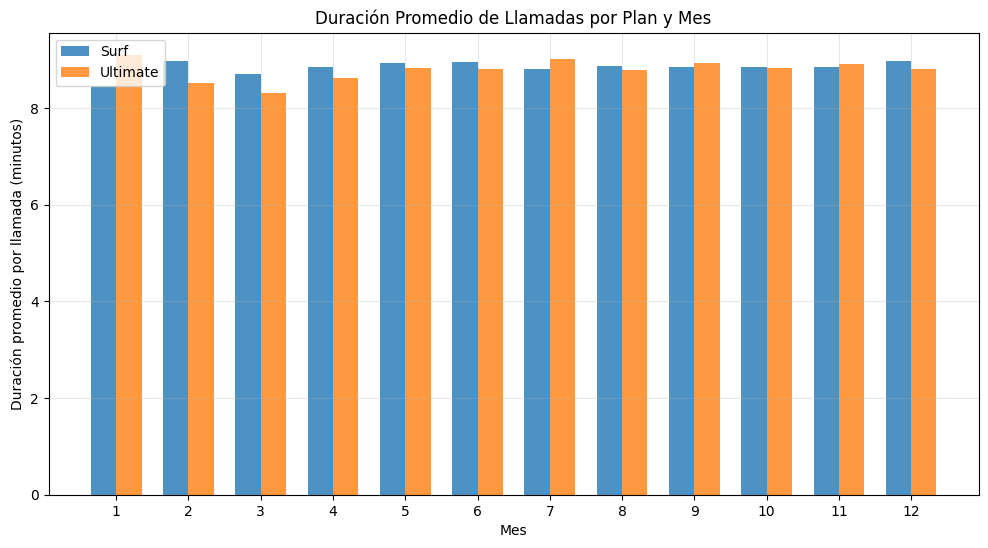

In [70]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.
# Crear gráfico de barras
plt.figure(figsize=(12, 6))
surf_data = avg_call_duration[avg_call_duration['plan'] == 'surf']
ultimate_data = avg_call_duration[avg_call_duration['plan'] == 'ultimate']

x = np.arange(len(surf_data['call_month']))
width = 0.35

plt.bar(x - width/2, surf_data['duration_billed'], width, label='Surf', alpha=0.8)
plt.bar(x + width/2, ultimate_data['duration_billed'], width, label='Ultimate', alpha=0.8)

plt.xlabel('Mes')
plt.ylabel('Duración promedio por llamada (minutos)')
plt.title('Duración Promedio de Llamadas por Plan y Mes')
plt.xticks(x, surf_data['call_month'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [71]:
# Calcula la media y la varianza de la duración mensual de llamadas.
monthly_call_duration = df_calls.merge(
    df_users[['user_id', 'plan']], 
    on='user_id'
).groupby(['user_id', 'plan', 'call_month'])['duration_billed'].sum().reset_index()

print("Duración mensual total por usuario:")
display(monthly_call_duration.head(10))

# Calcular media y varianza por plan
stats_by_plan = monthly_call_duration.groupby('plan')['duration_billed'].agg([
    'mean',
    'var',
    'std',
    'count',
    'median']).round(2)

print("Estadísticas de duración mensual de llamadas por plan:")
display(stats_by_plan)

#Comparar detallada entre planes
surf_duration = monthly_call_duration[monthly_call_duration['plan'] == 'surf']['duration_billed']
ultimate_duration = monthly_call_duration[monthly_call_duration['plan'] == 'ultimate']['duration_billed']

print("=== COMPARACIÓN DETALLADA ===")
print(f"Plan Surf:")
print(f"  Media: {surf_duration.mean():.2f} minutos")
print(f"  Varianza: {surf_duration.var():.2f}")
print(f"  Desviación estándar: {surf_duration.std():.2f}")

print(f"\nPlan Ultimate:")
print(f"  Media: {ultimate_duration.mean():.2f} minutos")
print(f"  Varianza: {ultimate_duration.var():.2f}")
print(f"  Desviación estándar: {ultimate_duration.std():.2f}")

Duración mensual total por usuario:


,user_id,plan,call_month,duration_billed
0,1000,ultimate,12,124.0
1,1001,surf,8,182.0
2,1001,surf,9,315.0
3,1001,surf,10,393.0
4,1001,surf,11,426.0
5,1001,surf,12,412.0
6,1002,surf,10,59.0
7,1002,surf,11,386.0
8,1002,surf,12,384.0
9,1003,surf,12,1104.0


Estadísticas de duración mensual de llamadas por plan:


,mean,var,std,count,median
plan,,,,,
surf,436.52,52571.06,229.28,1545,430.0
ultimate,434.68,56573.63,237.85,713,425.0


=== COMPARACIÓN DETALLADA ===
Plan Surf:
  Media: 436.52 minutos
  Varianza: 52571.06
  Desviación estándar: 229.28

Plan Ultimate:
  Media: 434.68 minutos
  Varianza: 56573.63
  Desviación estándar: 237.85


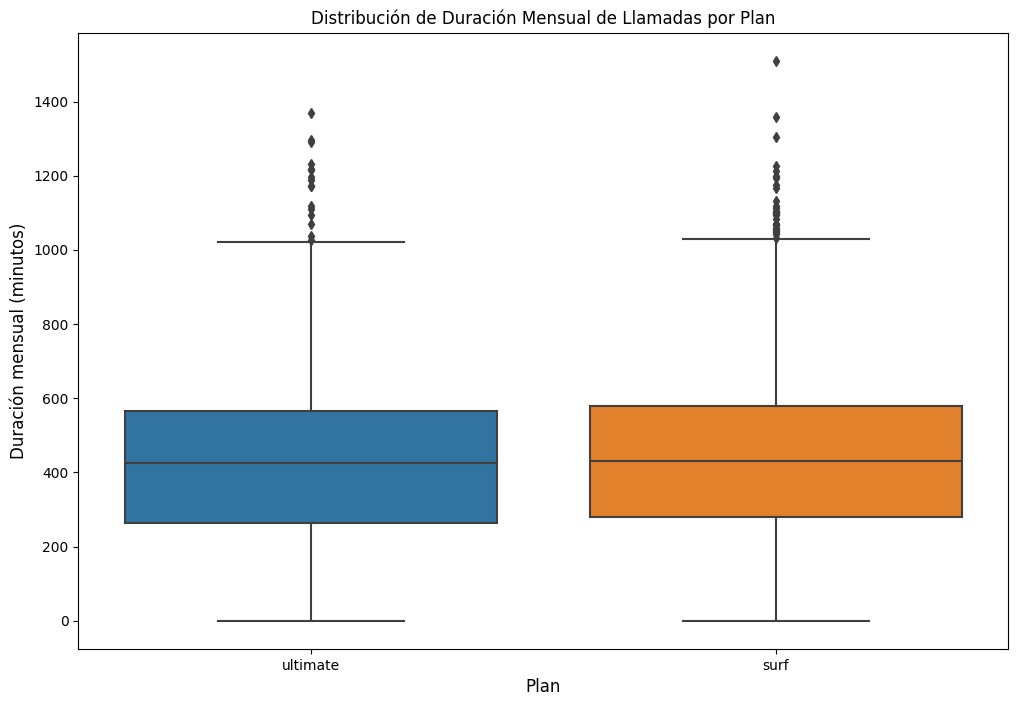

Medianas por plan:
plan
surf        430.0
ultimate    425.0
Name: duration_billed, dtype: float64
Número de outliers por plan:
plan
surf        28
ultimate    16
dtype: int64
=== ANÁLISIS DE OUTLIERS ===
Promedio de minutos de outliers Surf: 1138.71
Promedio de minutos de outliers Ultimate: 1175.69
Pago promedio adicional outliers Surf: $19.16
Pago promedio adicional outliers Ultimate: $0.00


In [72]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

plt.figure(figsize=(12, 8))
sns.boxplot(data=monthly_call_duration, x='plan', y='duration_billed')
plt.title('Distribución de Duración Mensual de Llamadas por Plan')
plt.ylabel('Duración mensual (minutos)', fontsize=12)
plt.xlabel('Plan', fontsize=12)
plt.show()

# Comparar medianas
print("Medianas por plan:")
print(monthly_call_duration.groupby('plan')['duration_billed'].median())

# Contar outliers por plan
outliers_count = monthly_call_duration.groupby('plan').apply(
    lambda x: len(x[x['duration_billed'] > x['duration_billed'].quantile(0.75) + 1.5 * (x['duration_billed'].quantile(0.75) - x['duration_billed'].quantile(0.25))]))
print("Número de outliers por plan:")
print(outliers_count)

# Identificar los outliers de Surf
surf_data = monthly_call_duration[monthly_call_duration['plan'] == 'surf']
Q1_surf = surf_data['duration_billed'].quantile(0.25)
Q3_surf = surf_data['duration_billed'].quantile(0.75)
IQR_surf = Q3_surf - Q1_surf
outliers_surf = surf_data[surf_data['duration_billed'] > Q3_surf + 1.5 * IQR_surf]

# Identificar los outliers de Ultimate
ultimate_data = monthly_call_duration[monthly_call_duration['plan'] == 'ultimate']
Q1_ultimate = ultimate_data['duration_billed'].quantile(0.25)
Q3_ultimate = ultimate_data['duration_billed'].quantile(0.75)
IQR_ultimate = Q3_ultimate - Q1_ultimate
outliers_ultimate = ultimate_data[ultimate_data['duration_billed'] > Q3_ultimate + 1.5 * IQR_ultimate]

print("=== ANÁLISIS DE OUTLIERS ===")
print(f"Promedio de minutos de outliers Surf: {outliers_surf['duration_billed'].mean():.2f}")
print(f"Promedio de minutos de outliers Ultimate: {outliers_ultimate['duration_billed'].mean():.2f}")

# Calcular cuánto pagan estos outliers por excesos
# Surf: $0.03 por minuto adicional después de 500 minutos
# Ultimate: $0.01 por minuto adicional después de 3000 minutos

surf_excess_avg = max(0, outliers_surf['duration_billed'].mean() - 500) * 0.03
ultimate_excess_avg = max(0, outliers_ultimate['duration_billed'].mean() - 3000) * 0.01

print(f"Pago promedio adicional outliers Surf: ${surf_excess_avg:.2f}")
print(f"Pago promedio adicional outliers Ultimate: ${ultimate_excess_avg:.2f}")

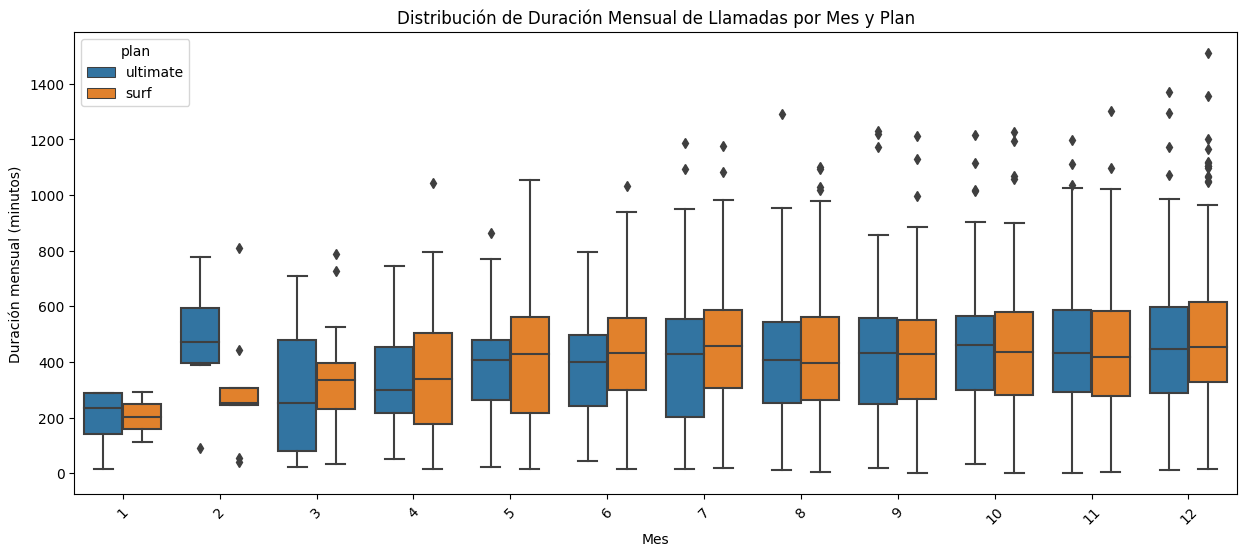

In [73]:
# Boxplot por mes para ver patrones temporales
plt.figure(figsize=(15, 6))
sns.boxplot(data=monthly_call_duration, x='call_month', y='duration_billed', hue='plan')
plt.title('Distribución de Duración Mensual de Llamadas por Mes y Plan')
plt.ylabel('Duración mensual (minutos)')
plt.xlabel('Mes')
plt.xticks(rotation=45)
plt.show()


- La variabilidad en el uso mensual de llamadas es muy parecida en ambos planes.
- El rango intercuatílico es similar.
- La caja de plan Surf aparece ligeramente posicionada un poco más arriba, lo que pdoría significar una mediana de minutos un poco mayor.
- El comportamiento de usuarios de Surf es usar más minutos que los de Ultimate.
- 28 usuarios tienen comportamientos de llamadas muy por encima del promedio, mientras que 16 usuarios de Ultimate están en esta categoría. Los usuarios de surf tienden a exceder más frecuentemente los límites normales.
- Estos 28 usuarios probablemente están pagando cargos adicionales significativos.
- El comportamiento mensual, nos muestra los patrones que hay mes con mes y observamos que cada mes tiene un patrón distinto.
- Observamos también que los primeros 3 meses el patrón de uso es distinto y a partir de junio se empieza a ver mas uniforme tanto en el tamaño como en la posición de las cajas.

### Mensajes

In [74]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

# Calcular mensajes mensuales por usuario 
monthly_messages = df_messages.merge(
    df_users[['user_id', 'plan']], 
    on='user_id'
).groupby(['user_id', 'plan', 'message_month'])['id'].count().reset_index()
monthly_messages = monthly_messages.rename(columns={'id': 'messages_count'})

print("Mensajes mensuales por usuario:")
display(monthly_messages.head(10))


Mensajes mensuales por usuario:


,user_id,plan,message_month,messages_count
0,1000,ultimate,12,11
1,1001,surf,8,30
2,1001,surf,9,44
3,1001,surf,10,53
4,1001,surf,11,36
5,1001,surf,12,44
6,1002,surf,10,15
7,1002,surf,11,32
8,1002,surf,12,41
9,1003,surf,12,50


In [75]:

# Calcular estadísticas por plan 
stats_messages_by_plan = monthly_messages.groupby('plan')['messages_count'].agg([
    'mean', 'var', 'std', 'count', 'median']).round(2)

print("Estadísticas de mensajes mensuales por plan:")
display(stats_messages_by_plan)

Estadísticas de mensajes mensuales por plan:


,mean,var,std,count,median
plan,,,,,
surf,40.11,1091.34,33.04,1222,32
ultimate,46.30,1085.18,32.94,584,41


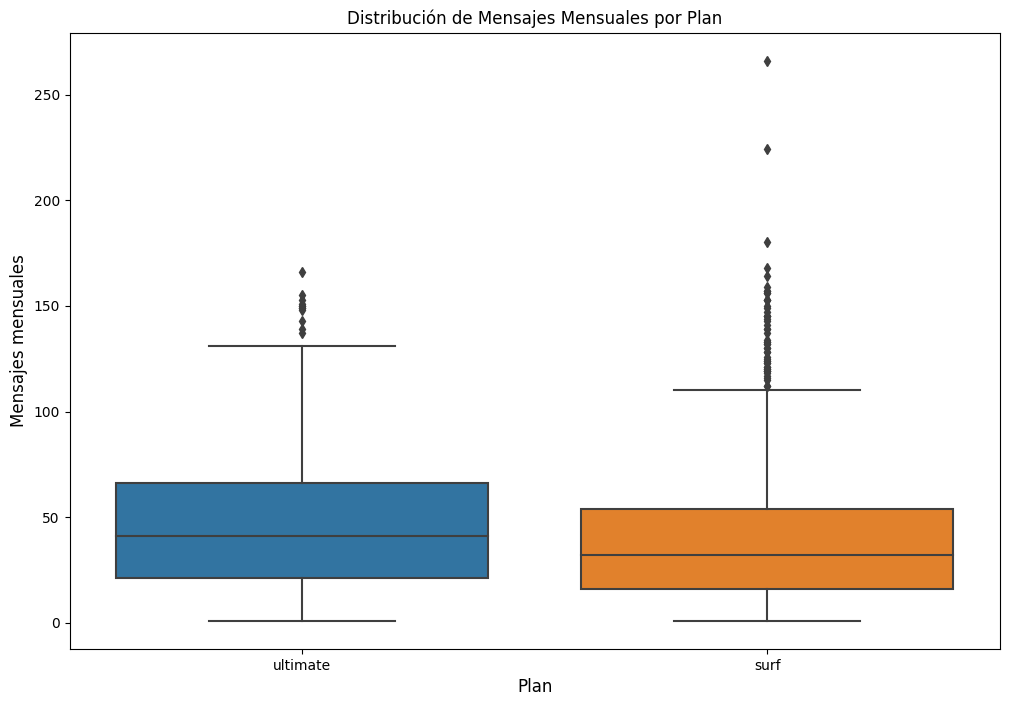

Medianas por plan:
plan
surf        32
ultimate    41
Name: messages_count, dtype: int64
Número de outliers por plan:
plan
surf        53
ultimate    12
dtype: int64


In [76]:


# Crear boxplot general
plt.figure(figsize=(12, 8))
sns.boxplot(data=monthly_messages, x='plan', y='messages_count')
plt.title('Distribución de Mensajes Mensuales por Plan')
plt.ylabel('Mensajes mensuales', fontsize=12)
plt.xlabel('Plan', fontsize=12)
plt.show()

# Calcular medianas y outliers
print("Medianas por plan:")
print(monthly_messages.groupby('plan')['messages_count'].median())

outliers_count_messages = monthly_messages.groupby('plan').apply(
    lambda x: len(x[x['messages_count'] > x['messages_count'].quantile(0.75) + 1.5 * (x['messages_count'].quantile(0.75) - x['messages_count'].quantile(0.25))]))
print("Número de outliers por plan:")
print(outliers_count_messages)



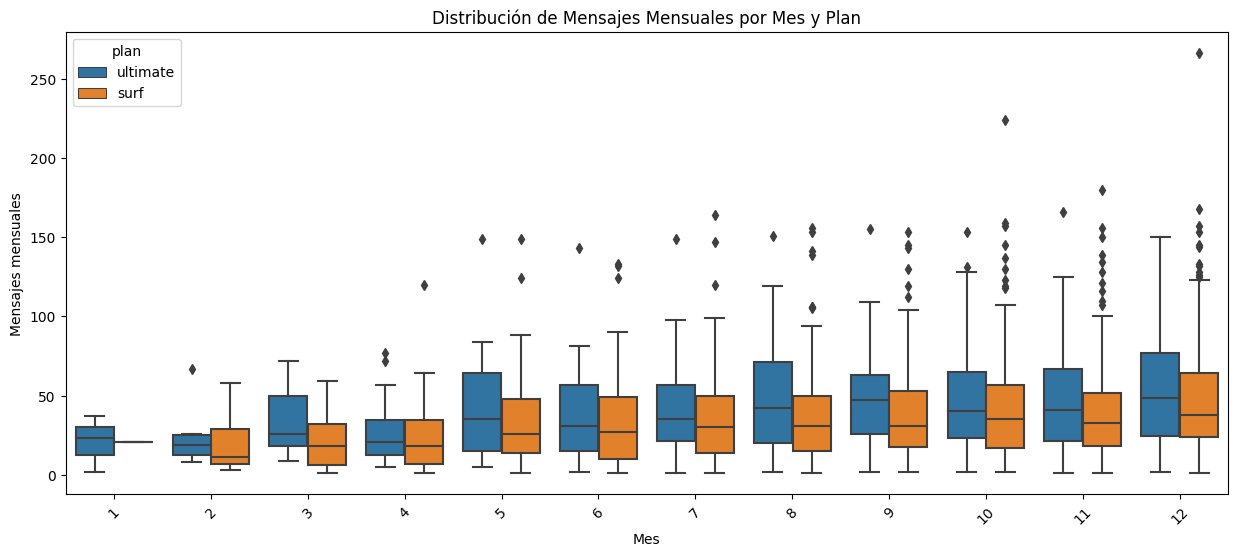

In [77]:


# Crear boxplot mensual 
plt.figure(figsize=(15, 6))
sns.boxplot(data=monthly_messages, x='message_month', y='messages_count', hue='plan')
plt.title('Distribución de Mensajes Mensuales por Mes y Plan')
plt.ylabel('Mensajes mensuales')
plt.xlabel('Mes')
plt.xticks(rotation=45)
plt.show()




Comparación: Llamadas vs Mensajes

Medianas:
-Llamadas: Surf (405.71) vs Ultimate (399.98) --> son muy similares.
-Mensajes: Surf (32) vs Ultimate (41) --> Ultimate 28% más alto.

Outliers:
- Llamadas: Surf (28) vs Ultimate (16) --> Surf tiene el doble
- Mensajes: Surf (53) vs Ultimate (12) --> Surf tiene más de 4 veces
  
Hay mayor variabilidad en el uso de mensajes para usuarios Surf


### Internet

In [79]:

# Calcular GB mensuales por usuario 
monthly_internet = df_internet.merge(
    df_users[['user_id', 'plan']], 
    on='user_id'
).groupby(['user_id', 'plan', 'session_month'])['gb_used'].sum().reset_index()
monthly_internet = monthly_internet.rename(columns={'gb_used': 'monthly_gb_used'})

print("GB mensuales por usuario:")
display(monthly_internet.head(10))

# Calcular estadísticas por plan 
stats_internet_by_plan = monthly_internet.groupby('plan')['monthly_gb_used'].agg([
    'mean', 'var', 'std', 'count', 'median'
]).round(2)

print("Estadísticas de GB mensuales por plan:")
display(stats_internet_by_plan)


GB mensuales por usuario:


,user_id,plan,session_month,monthly_gb_used
0,1000,ultimate,12,1.856904
1,1001,surf,8,6.756982
2,1001,surf,9,13.002754
3,1001,surf,10,21.807119
4,1001,surf,11,18.070605
5,1001,surf,12,18.915215
6,1002,surf,10,6.398447
7,1002,surf,11,18.891680
8,1002,surf,12,14.058828
9,1003,surf,12,26.410293


Estadísticas de GB mensuales por plan:


,mean,var,std,count,median
plan,,,,,
surf,16.33,59.29,7.70,1558,16.53
ultimate,16.83,58.48,7.65,719,16.47


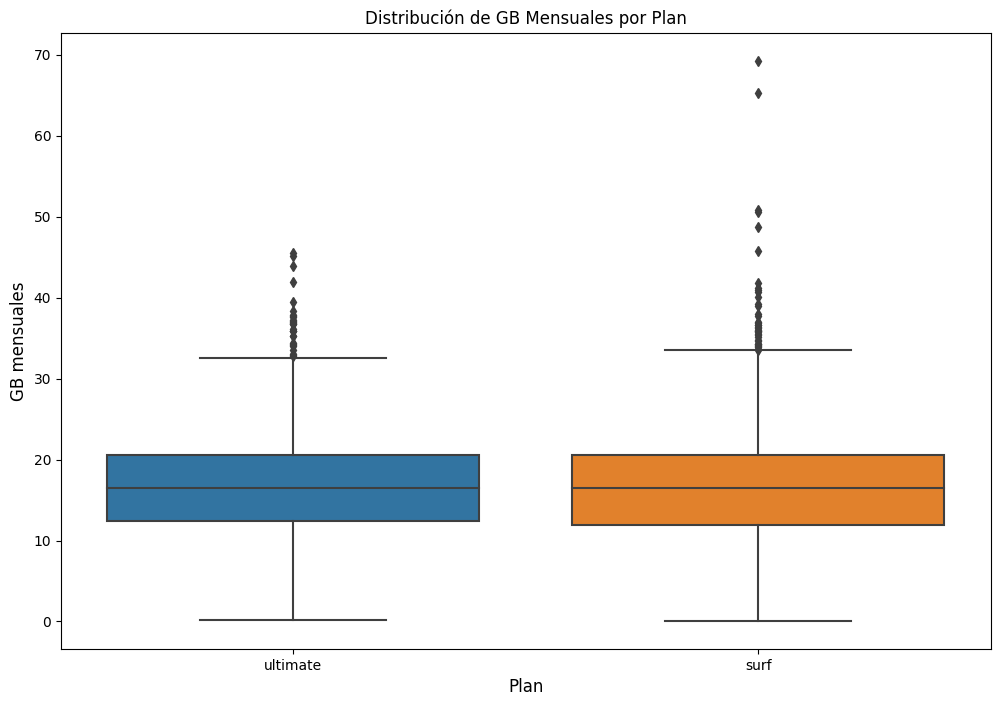

Medianas por plan:
plan
surf        16.527178
ultimate    16.468213
Name: monthly_gb_used, dtype: float64
Número de outliers por plan:
plan
surf        37
ultimate    29
dtype: int64


In [80]:

# Compara la cantidad de tráfico de Internet consumido por usuarios por plan
# Crear boxplot general 
plt.figure(figsize=(12, 8))
sns.boxplot(data=monthly_internet, x='plan', y='monthly_gb_used')
plt.title('Distribución de GB Mensuales por Plan')
plt.ylabel('GB mensuales', fontsize=12)
plt.xlabel('Plan', fontsize=12)
plt.show()

# Calcular medianas y outliers
print("Medianas por plan:")
print(monthly_internet.groupby('plan')['monthly_gb_used'].median())

outliers_count_internet = monthly_internet.groupby('plan').apply(
    lambda x: len(x[x['monthly_gb_used'] > x['monthly_gb_used'].quantile(0.75) + 1.5 * (x['monthly_gb_used'].quantile(0.75) - x['monthly_gb_used'].quantile(0.25))]))
print("Número de outliers por plan:")
print(outliers_count_internet)


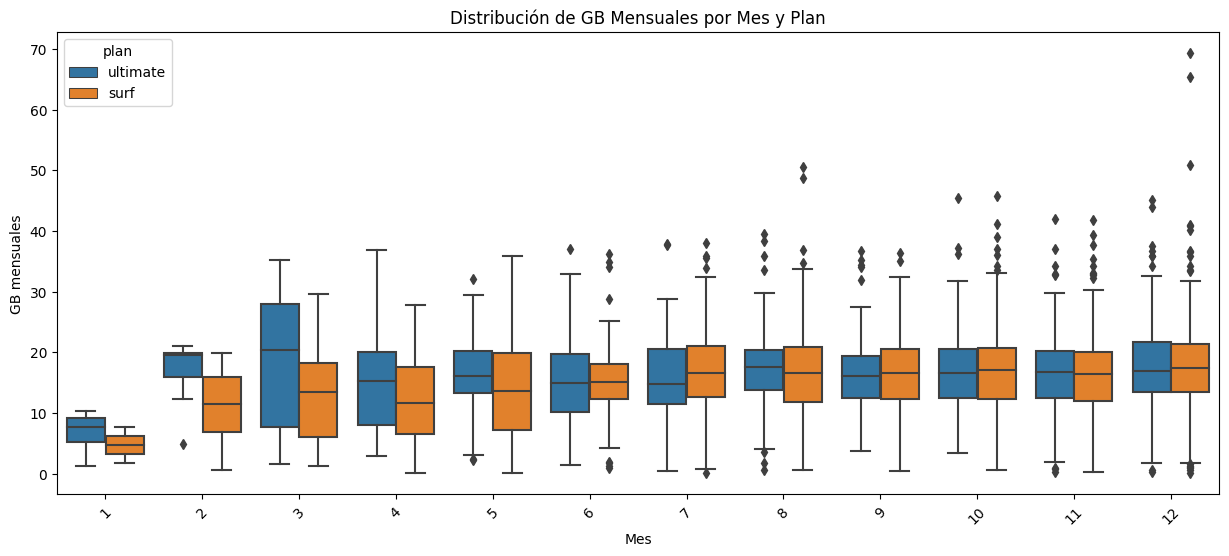

In [81]:


# Crear boxplot mensual para internet
plt.figure(figsize=(15, 6))
sns.boxplot(data=monthly_internet, x='session_month', y='monthly_gb_used', hue='plan')
plt.title('Distribución de GB Mensuales por Mes y Plan')
plt.ylabel('GB mensuales')
plt.xlabel('Mes')
plt.xticks(rotation=45)
plt.show()




- Las medianas en ambos planes son muy similares, sin embargo el plan Ultimate incluye el doble que surf. Un usuario típico usa al rededor de 16-17 GB en ambos planes, incluso con más GB disponibles en plan Ultimate, esto no es motivo para que se usen, sin embargo los usuarios lo están pagando. 
- La rentabilidad de los outliers en este rubro son particularmente importantes debido a que los cargos por excesos son altos (10 para Surf, y 7 para Ultimate)
- Surf tiene más outliers, lo cual indica que usan más de lo normal.
- En el analisis mensual obserbamos que existen grupos de usuarios que usan muy poco internet en algunos meses como febrero, mayo a agosto, y noviembre y diciembre.
  

In [82]:


# Calcular estadísticas descriptivas de ingresos por plan
revenue_stats = user_data_complete.groupby('plan')['monthly_revenue'].agg([
    'mean', 'median', 'std', 'var', 'min', 'max', 'count'
]).round(2)

print("Estadísticas de ingresos mensuales por plan:")
display(revenue_stats)

# Comparación detallada
surf_revenue = user_data_complete[user_data_complete['plan'] == 'surf']['monthly_revenue']
ultimate_revenue = user_data_complete[user_data_complete['plan'] == 'ultimate']['monthly_revenue']

print("\n=== COMPARACIÓN DETALLADA DE INGRESOS ===")
print(f"Plan Surf:")
print(f"  Media: ${surf_revenue.mean():.2f}")
print(f"  Mediana: ${surf_revenue.median():.2f}")
print(f"  Desviación estándar: ${surf_revenue.std():.2f}")

print(f"\nPlan Ultimate:")
print(f"  Media: ${ultimate_revenue.mean():.2f}")
print(f"  Mediana: ${ultimate_revenue.median():.2f}")
print(f"  Desviación estándar: ${ultimate_revenue.std():.2f}")



Estadísticas de ingresos mensuales por plan:


,mean,median,std,var,min,max,count
plan,,,,,,,
surf,60.71,40.36,55.39,3067.84,20.0,590.37,1573
ultimate,72.31,70.00,11.40,129.85,70.0,182.00,720



=== COMPARACIÓN DETALLADA DE INGRESOS ===
Plan Surf:
  Media: $60.71
  Mediana: $40.36
  Desviación estándar: $55.39

Plan Ultimate:
  Media: $72.31
  Mediana: $70.00
  Desviación estándar: $11.40


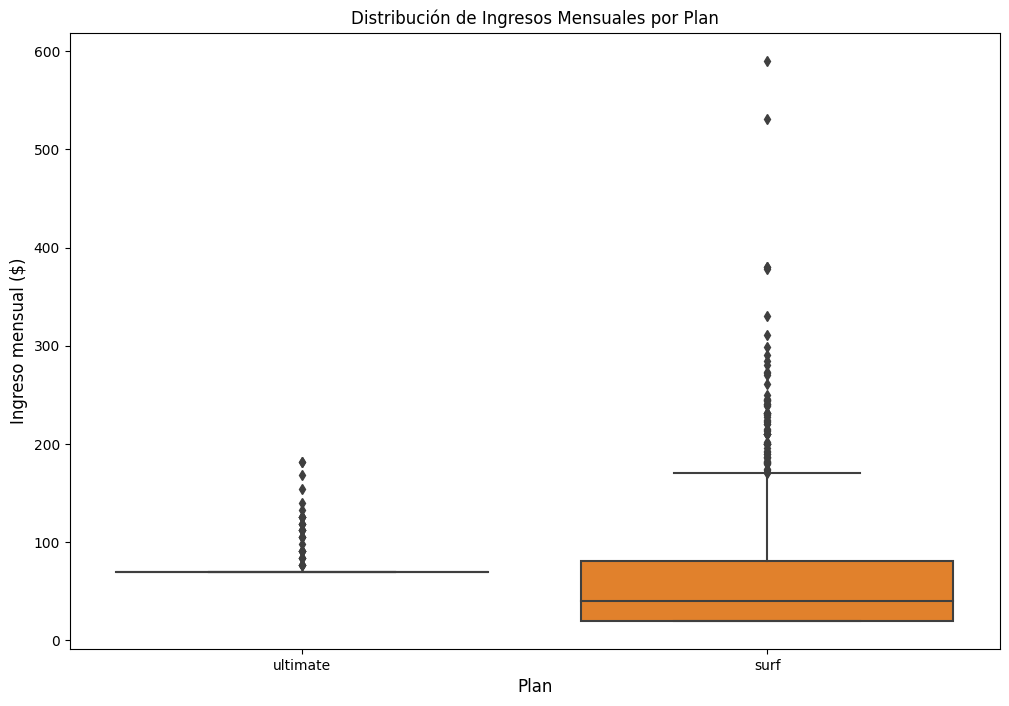

Número de outliers de ingresos por plan:
plan
surf        71
ultimate    41
dtype: int64


In [83]:


# Crear boxplot para comparar distribución de ingresos
plt.figure(figsize=(12, 8))
sns.boxplot(data=user_data_complete, x='plan', y='monthly_revenue')
plt.title('Distribución de Ingresos Mensuales por Plan')
plt.ylabel('Ingreso mensual ($)', fontsize=12)
plt.xlabel('Plan', fontsize=12)
plt.show()

# Identificar outliers
outliers_revenue = user_data_complete.groupby('plan').apply(
    lambda x: len(x[x['monthly_revenue'] > x['monthly_revenue'].quantile(0.75) + 
                   1.5 * (x['monthly_revenue'].quantile(0.75) - x['monthly_revenue'].quantile(0.25))])
)
print("Número de outliers de ingresos por plan:")
print(outliers_revenue)



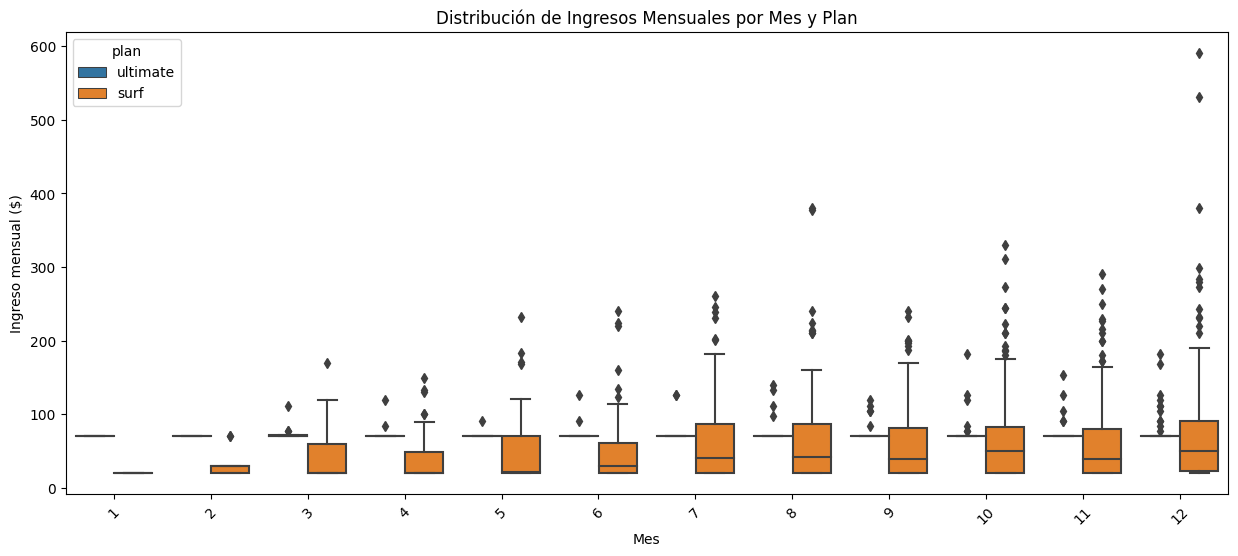

Ingreso promedio mensual por plan:


plan,surf,ultimate
month,,
1,20.00,70.00
2,34.40,70.00
3,45.94,74.67
4,40.71,73.00
5,47.63,70.72
6,49.28,71.64
7,62.67,71.90
8,63.93,72.86
9,58.27,72.03


In [84]:


# Análisis de ingresos por mes y plan
plt.figure(figsize=(15, 6))
sns.boxplot(data=user_data_complete, x='month', y='monthly_revenue', hue='plan')
plt.title('Distribución de Ingresos Mensuales por Mes y Plan')
plt.ylabel('Ingreso mensual ($)')
plt.xlabel('Mes')
plt.xticks(rotation=45)
plt.show()

# Calcular ingresos promedio por mes y plan
monthly_revenue_avg = user_data_complete.groupby(['plan', 'month'])['monthly_revenue'].mean().reset_index()
print("Ingreso promedio mensual por plan:")
display(monthly_revenue_avg.pivot(index='month', columns='plan', values='monthly_revenue').round(2))



Conclusiones sobre cómo difiere el ingreso entre los planes

- Analizando las cajas de los gráficos, vemos que la del plan Surf es mas grande, lo que indica alta variabilidad de ingresos. La mediana es de 40.36,pero hay mucha dispersión y la desviación estándar es alta.
- Ultimate tiene cajas prácticamente inapreciables, una mediana de 70.00 y desviacion estandar baja.
- Muchos usuarios surf pagan solo 20.00 de base, pero algunos exceden límites y pagan mucho mas, lo que genera una gran dispersión en ingresos.
- La mayoría de plan Ultimate paga los 70.00 de base ya que los límites son generosos y pocos usuarios exceden estos límites.
- Surf es mas impredecible pero puede generar ingresos altos por los excesos.
- Ultimate es más estable y predecible en ingresos.
- Los usuarios de Surf respresentan usuarios que pagan significativamente mas.
  

## Prueba las hipótesis estadísticas






- Hipótesis nula: Los ingresos promedio de los usuarios del plan Surf son iguales a los ingresos promedio de los usuarios del plan Ultimate.
- Hipótesis alternativa: Los ingresos promedio de los usuarios del plan Surf son diferentes a los ingresos promedio de los usuarios del plan ultimate.




In [85]:
# Prueba las hipótesis


ingresos_surf = user_data_complete[user_data_complete['plan'] == 'surf']['monthly_revenue'] 
ingresos_ultimate = user_data_complete[user_data_complete['plan'] == 'ultimate']['monthly_revenue']

print(f"Número de registros Surf: {len(ingresos_surf)}")
print(f"Número de registros Ultimate: {len(ingresos_ultimate)}")

print("=== PLAN SURF ===")
print(f"Media: ${ingresos_surf.mean():.2f}")
print(f"Mediana: ${ingresos_surf.median():.2f}")

print("\n=== PLAN ULTIMATE ===") 
print(f"Media: ${ingresos_ultimate.mean():.2f}")
print(f"Mediana: ${ingresos_ultimate.median():.2f}")



Número de registros Surf: 1573
Número de registros Ultimate: 720
=== PLAN SURF ===
Media: $60.71
Mediana: $40.36

=== PLAN ULTIMATE ===
Media: $72.31
Mediana: $70.00


In [86]:
# Realizar la prueba t de Student (sin prueba de Levene)
from scipy.stats import ttest_ind

# Nivel de significancia
alpha = 0.05

# Prueba t de dos muestras independientes
# Usamos equal_var=False para ser más conservadores
t_stat, p_value = ttest_ind(ingresos_surf, ingresos_ultimate, equal_var=False)

print(f"=== RESULTADOS DE LA PRUEBA T ===")
print(f"Estadístico t: {t_stat:.4f}")
print(f"P-valor: {p_value:.4f}")
print(f"Nivel de significancia (α): {alpha}")



# Interpretación de resultados
print(f"\n=== DECISIÓN SOBRE LAS HIPÓTESIS ===")
if p_value < alpha:
    print(" RECHAZAMOS la hipótesis nula")
    print(" ACEPTAMOS la hipótesis alternativa")
    print(" Conclusión: Los ingresos promedio de Surf y Ultimate SÍ son significativamente diferentes")
else:
    print(" NO podemos rechazar la hipótesis nula")
    print(" Conclusión: No hay evidencia suficiente de diferencia significativa")

print(f"\n Diferencia observada:")
print(f"   • Surf: ${ingresos_surf.mean():.2f}")
print(f"   • Ultimate: ${ingresos_ultimate.mean():.2f}")
print(f" Ultimate genera ${ingresos_ultimate.mean() - ingresos_surf.mean():.2f} más en promedio")
    

    

=== RESULTADOS DE LA PRUEBA T ===
Estadístico t: -7.9521
P-valor: 0.0000
Nivel de significancia (α): 0.05

=== DECISIÓN SOBRE LAS HIPÓTESIS ===
 RECHAZAMOS la hipótesis nula
 ACEPTAMOS la hipótesis alternativa
 Conclusión: Los ingresos promedio de Surf y Ultimate SÍ son significativamente diferentes

 Diferencia observada:
   • Surf: $60.71
   • Ultimate: $72.31
 Ultimate genera $11.61 más en promedio



- Hipótesis nula: El ingreso promedio de usuarios de NY-NJ es igual al de otras regiones.
- Hipótesis alternativa: El ingreso promedio de usuarios de NY-NJ es diferente al de otras regiones.



In [87]:
# Prueba las hipótesis

# Identificar usuarios de NY-NJ
user_data_complete['is_ny_nj'] = user_data_complete['user_id'].map(
    lambda x: df_users[df_users['user_id'] == x]['city'].iloc[0]
).str.contains('New York-Newark-Jersey City, NY-NJ-PA MSA', na=False)

# Verificar la clasificación
print("Distribución de usuarios por región:")
print(user_data_complete['is_ny_nj'].value_counts())

# Separar ingresos por región
ingresos_ny_nj = user_data_complete[user_data_complete['is_ny_nj'] == True]['monthly_revenue']
ingresos_otras_regiones = user_data_complete[user_data_complete['is_ny_nj'] == False]['monthly_revenue']

# Verificar los datos
print(f"Registros NY-NJ: {len(ingresos_ny_nj)}")
print(f"Registros otras regiones: {len(ingresos_otras_regiones)}")
print(f"Ingreso promedio NY-NJ: ${ingresos_ny_nj.mean():.2f}")
print(f"Ingreso promedio otras regiones: ${ingresos_otras_regiones.mean():.2f}")



Distribución de usuarios por región:
False    1916
True      377
Name: is_ny_nj, dtype: int64
Registros NY-NJ: 377
Registros otras regiones: 1916
Ingreso promedio NY-NJ: $59.92
Ingreso promedio otras regiones: $65.22


In [88]:

# Prueba T de Student
from scipy.stats import ttest_ind

# Nivel de significacia
alpha = 0.05

# Prueba t de dos muestras independientes (NY-NJ vs otras regiones)

t_stat_region, p_value_region = ttest_ind(ingresos_ny_nj, ingresos_otras_regiones, equal_var=False)

print(f"=== RESULTADOS DE LA PRUEBA T (REGIONES) ===")
print(f"Estadístico t: {t_stat_region:.4f}")
print(f"P-valor: {p_value_region:.4f}")
print(f"Nivel de significancia (α): {alpha}")

# Interpretación de resultados
print(f"\n=== DECISIÓN SOBRE LAS HIPÓTESIS ===")
if p_value_region < alpha:
    print("RECHAZAMOS la hipótesis nula")
    print("ACEPTAMOS la hipótesis alternativa")
    print("Conclusión: Los ingresos promedio de NY-NJ y otras regiones SÍ son significativamente diferentes")
else:
    print("NO podemos rechazar la hipótesis nula")
    print("Conclusión: No hay evidencia suficiente de diferencia significativa entre regiones")

print(f"\n Diferencia observada:")
print(f"   • NY-NJ: ${ingresos_ny_nj.mean():.2f}")
print(f"   • Otras regiones: ${ingresos_otras_regiones.mean():.2f}")
diferencia = ingresos_otras_regiones.mean() - ingresos_ny_nj.mean()
print(f" Otras regiones generan ${diferencia:.2f} más en promedio que NY-NJ")


=== RESULTADOS DE LA PRUEBA T (REGIONES) ===
Estadístico t: -2.1309
P-valor: 0.0335
Nivel de significancia (α): 0.05

=== DECISIÓN SOBRE LAS HIPÓTESIS ===
RECHAZAMOS la hipótesis nula
ACEPTAMOS la hipótesis alternativa
Conclusión: Los ingresos promedio de NY-NJ y otras regiones SÍ son significativamente diferentes

 Diferencia observada:
   • NY-NJ: $59.92
   • Otras regiones: $65.22
 Otras regiones generan $5.30 más en promedio que NY-NJ


## Conclusión general



OBJETIVO DEL PROYECTO:
Determinar cual de los planes de Megaline: surf vs ultimate, genera más ingresos analizando a 500 clientes durante 2018.

Principales hallazgos:

1. Comparación de planes:
  - Plan Ultimate es significativamente más rentable.
  - Hay diferencia de 11.61 más en costo por usuario al mes.
  - El p-valor 0.0000 es altamente significativo.
  - El presupuesto se recomienda enfocarlo en promocionar Ultimate.
  - Después de aplicar el redondeo correcto, sa validó la superioridad estadística del plan Ultimate
    
2. Análisis regional (NY-NJ vs Otras regiones):
   - Otras regiones generan más ingresos que NY-NJ
   - La diferencia por usuario es de 5.30 más al mes.
   - P-valor = 0.035 es significativo.
   - Desarrollar estrategias diferenciadas para NY-NJ vs otras regiones como investigar por qué los ingresos son menores o desarrollar ofertas más competitivas en esa región.
     
Recomendaciones para el negocio:
1. Priorizar en invertir más presupuesto publicitario en promocionar Ultimate
2. Desarrollar diferenciadores estratégicos enfocados para NY-NJ.
3. Ultimate genera 21% mas ingresos por usuario que Surf, por lo que migrar usuarios Surf a Ultimate podría ser clave para el crecimiento del negocio.
5. Enfocar esfuerzos en regiones fuera de NY-NJ, donde los ingresos son mayores.

 